# CS 418 Progress Report: Housing Prices and Crime Across Chicago Community Areas
**Team:** [Lorentz Factor] | **Members:** [Simon termigali, Anthony Martinez, Joonho Ma, Ajani Lazo, Hector Castro] | **Repo:** [GitHub link]



## 1. Project introduction
**Question:** Do Chicago community areas with higher home sale prices have lower crime rates, and can housing characteristics predict an area's crime level?

**Data**
- *Chicago Crimes, 2001 to Present* (City of Chicago Data Portal): one row per reported incident, with type, date, community area, and coordinates.
- *Assessor, Parcel Sales* (Cook County Data Portal): one row per property sale, with PIN, sale date, price, and deed and class information.
- *Assessor, Parcel Universe* (Cook County): used only to attach latitude/longitude to each PIN, because the sales table has no location.
- *Community Area boundaries* (City of Chicago): the 77 areas used as the shared geographic unit.

**Hypothesis:** [edit?] Higher median sale price is associated with a lower crime rate at the community area level.

## 2. Changes since the proposal
[TODO: ]

## 3. Setup and data loading

In [ ]:
%pip install -q geopandas scikit-learn scipy matplotlib

In [ ]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DATA_DIR = "data"   # local folder not comitted to git, create folder in your local repo and add datasets

CRIME_FILE = "Crimes_-_2001_to_Present_20261031.csv"
SALES_FILE = "Assessor_-_Parcel_Sales_20261031.csv"
UNIVERSE_FILE = "Assessor_-_Parcel_Universe_(Current)_20261101.csv"
AREAS_FILE = "community_areas.geojson"
 #POP_FILE = "community_area_population.csv"        # future file to normalize pop

START_DATE = "2021-01-01"   # same window for both datasets
MIN_PRICE = 10_000          # drops $0/$1 and other non-market transfers
# City of Chicago townships (Cook County township codes 70-77)
CHICAGO_TOWNSHIPS = {70, 71, 72, 73, 74, 75, 76, 77}
AREAS_URL = "https://data.cityofchicago.org/resource/igwz-8jzy.geojson"


def norm_cols(df):
    df.columns = [re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_") for c in df.columns]
    return df

cleaning_log = []
def log(dataset, step, n):
    cleaning_log.append({"dataset": dataset, "step": step, "rows": n})
    print(f"{dataset:8s} | {step:55s} | {n:>10,}")

## 4. Data cleaning
### 4a. Crimes (filtered while reading, because the full file is millions of rows)

In [21]:
path = os.path.join(DATA_DIR, CRIME_FILE)
header = norm_cols(pd.read_csv(path, nrows=0)).columns.tolist()
want = ["id", "date", "primary_type", "description", "arrest", "domestic", "community_area", "latitude", "longitude"]
usecols = [c for c in want if c in header]
print("columns kept:", usecols)

chunks, total = [], 0
for ch in pd.read_csv(path, usecols=lambda c: re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_") in usecols,
                      chunksize=500_000, low_memory=False):
    ch = norm_cols(ch)
    total += len(ch)
    ch["date"] = pd.to_datetime(ch["date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    chunks.append(ch[ch["date"] >= START_DATE])
crime = pd.concat(chunks, ignore_index=True)
del chunks
log("crime", "raw rows in file (2001 to present)", total)
log("crime", f"date >= {START_DATE}", len(crime))

crime = crime.drop_duplicates(subset="id");                       log("crime", "drop duplicate IDs", len(crime))
crime = crime.dropna(subset=["community_area"]);                  log("crime", "drop missing community area", len(crime))
crime["community_area"] = crime["community_area"].astype(int)
crime = crime[crime["community_area"].between(1, 77)];            log("crime", "keep community areas 1-77", len(crime))
crime.head()

columns kept: ['id', 'date', 'primary_type', 'description', 'arrest', 'domestic', 'community_area', 'latitude', 'longitude']
crime    | raw rows in file (2001 to present)                      |  8,670,365
crime    | date >= 2021-01-01                                      |  1,401,583
crime    | drop duplicate IDs                                      |  1,401,583
crime    | drop missing community area                             |  1,401,469
crime    | keep community areas 1-77                               |  1,399,542


,id,date,primary_type,description,arrest,domestic,community_area,latitude,longitude
0,14368472,2026-10-23,THEFT,THEFT FROM MOTOR VEHICLE,False,False,68,41.766399,-87.646877
1,14369392,2026-10-23,BATTERY,DOMESTIC BATTERY SIMPLE,False,True,73,41.720909,-87.640768
2,14373775,2026-10-23,THEFT,$500 AND UNDER,False,False,45,NaN,NaN
3,14368835,2026-10-23,DECEPTIVE PRACTICE,FRAUD OR CONFIDENCE GAME,False,False,70,41.749738,-87.700782
4,14368046,2026-10-23,ASSAULT,SIMPLE,False,False,69,41.768692,-87.624942


### 4b. Parcel sales

In [ ]:
sales = norm_cols(pd.read_csv(os.path.join(DATA_DIR, SALES_FILE), low_memory=False))
log("sales", "raw rows in file", len(sales))
print(sales.columns.tolist())

sales["sale_date"] = pd.to_datetime(sales["sale_date"], errors="coerce")
sales["sale_price"] = pd.to_numeric(
    sales["sale_price"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)
sales["pin"] = sales["pin"].astype(str).str.replace("-", "", regex=False).str.zfill(14)

sales = sales[sales["sale_date"] >= START_DATE];                  log("sales", f"sale_date >= {START_DATE}", len(sales))
sales = sales.dropna(subset=["sale_price"]);                      log("sales", "drop missing price", len(sales))
sales = sales[sales["sale_price"] > MIN_PRICE];                   log("sales", f"price > ${MIN_PRICE:,}", len(sales))

if "is_multisale" in sales.columns:
    sales = sales[~sales["is_multisale"].astype(str).str.lower().isin(["true", "1", "t", "yes"])]
    log("sales", "drop multi-parcel sales", len(sales))

if "township_code" in sales.columns:
    sales = sales[pd.to_numeric(sales["township_code"], errors="coerce").isin(CHICAGO_TOWNSHIPS)]
    log("sales", "keep City of Chicago townships", len(sales))

# residential classes only. Assessor classes 2xx are residential
if "class" in sales.columns:
    sales["class"] = sales["class"].astype(str)
    sales = sales[sales["class"].str.startswith("2")];            log("sales", "residential property classes (2xx)", len(sales))

sales = sales.drop_duplicates(subset=["pin", "sale_date", "sale_price"]);  log("sales", "drop duplicate sales", len(sales))
sales.head()

sales    | raw rows in file                                        |  2,688,811
['pin', 'year', 'township_code', 'neighborhood_code', 'class', 'sale_date', 'is_mydec_date', 'sale_price', 'sale_document_num', 'sale_deed_type', 'mydec_deed_type', 'sale_seller_name', 'is_multisale', 'num_parcels_sale', 'sale_buyer_name', 'sale_type', 'sale_filter_same_sale_within_365', 'sale_filter_less_than_10k', 'sale_filter_deed_type', 'row_id']
sales    | sale_date >= 2021-01-01                                 |    476,356
sales    | drop missing price                                      |    476,356
sales    | price > $10,000                                         |    470,708
sales    | drop multi-parcel sales                                 |    359,780
sales    | keep City of Chicago townships                          |    171,235
sales    | residential property classes (2xx)                      |    162,735
sales    | drop duplicate sales                                    |    162,726


,pin,year,township_code,neighborhood_code,class,sale_date,is_mydec_date,sale_price,sale_document_num,sale_deed_type,mydec_deed_type,sale_seller_name,is_multisale,num_parcels_sale,sale_buyer_name,sale_type,sale_filter_same_sale_within_365,sale_filter_less_than_10k,sale_filter_deed_type,row_id
1,25151170160000,2023,70,70220,203,2023-01-18,True,160000,2303046131,Warranty,Warranty Deed,HENRIETTA PLAIR,False,1,HULA HUT HOLDINGS LLC,NaN,False,False,False,7446040
2,20023020390000,2023,70,70010,205,2023-01-19,True,40000,2302425000,Warranty,Warranty Deed,JOHN CLEMON FEARN,False,1,"BLACKBOX CONSTRUCTION, LLC",NaN,False,False,False,7446041
3,20114000191005,2023,70,70020,299,2023-01-10,True,244000,2302310256,Warranty,Warranty Deed,ARTHUR F HILL,False,1,SOPHIE VEYS,NaN,False,False,False,7446042
4,20352090130000,2023,70,70080,203,2023-01-25,True,55000,2302546166,Warranty,Warranty Deed,"DERRICK JACKSON, II",False,1,MARK TERRELL,NaN,False,False,False,7446052
5,25032210120000,2023,70,70120,211,2023-01-26,True,299900,2302741037,Warranty,Warranty Deed,JOHN B BATSON,False,1,BRUNETTA WASHINGTON,NaN,False,False,False,7446054


### 4c. Attach locations to sales
The sales table has no coordinates, so each PIN is matched to the downloaded Parcel Universe CSV (set by `UNIVERSE_FILE` in the config cell), which provides latitude and longitude.

In [23]:
uni = norm_cols(pd.read_csv(os.path.join(DATA_DIR, UNIVERSE_FILE), low_memory=False))
lat_c = next(c for c in uni.columns if c in ("lat", "latitude", "y_3435"))
lon_c = next(c for c in uni.columns if c in ("lon", "longitude", "x_3435"))
uni = uni.rename(columns={lat_c: "lat", lon_c: "lon"})
uni["pin"] = uni["pin"].astype(str).str.replace("-", "", regex=False).str.zfill(14)
uni = uni[["pin", "lat", "lon"]].dropna().drop_duplicates("pin")

sales = sales.merge(uni, on="pin", how="inner");                  log("sales", "matched to Parcel Universe coordinates", len(sales))

sales    | matched to Parcel Universe coordinates                  |    160,297


### 4d. Assign each sale to a community area (spatial join)

In [24]:
apath = os.path.join(DATA_DIR, AREAS_FILE)
areas = gpd.read_file(apath if os.path.exists(apath) else AREAS_URL).to_crs("EPSG:4326")
area_col = next(c for c in areas.columns if c in ("area_numbe", "area_num_1", "area_number", "community_area"))
names_col = next((c for c in areas.columns if c in ("community", "community_area_name")), None)
areas["community_area"] = areas[area_col].astype(int)

pts = gpd.GeoDataFrame(sales, geometry=gpd.points_from_xy(sales["lon"], sales["lat"]), crs="EPSG:4326")
sales = gpd.sjoin(pts, areas[["community_area", "geometry"]], how="inner", predicate="within")
sales = pd.DataFrame(sales.drop(columns=["geometry", "index_right"]))
log("sales", "points inside a Chicago community area", len(sales))

pd.DataFrame(cleaning_log)

sales    | points inside a Chicago community area                  |    160,297


,dataset,step,rows
0,crime,raw rows in file (2001 to present),8670365
1,crime,date >= 2021-01-01,1401583
2,crime,drop duplicate IDs,1401583
3,crime,drop missing community area,1401469
4,crime,keep community areas 1-77,1399542
5,sales,raw rows in file,2688811
6,sales,sale_date >= 2021-01-01,476356
7,sales,drop missing price,476356
8,sales,"price > $10,000",470708
9,sales,drop multi-parcel sales,359780


### 4e. One row per community area

In [25]:
years = (pd.Timestamp(crime["date"].max()) - pd.Timestamp(START_DATE)).days / 365.25
violent_types = ["HOMICIDE", "ASSAULT", "BATTERY", "ROBBERY", "CRIMINAL SEXUAL ASSAULT", "CRIM SEXUAL ASSAULT"]

table = pd.DataFrame(index=pd.Index(range(1, 78), name="community_area"))
table["crime_count"] = crime.groupby("community_area").size()
table["violent_count"] = crime[crime["primary_type"].isin(violent_types)].groupby("community_area").size()
table["violent_share"] = table["violent_count"] / table["crime_count"]
g = sales.groupby("community_area")["sale_price"]
table["median_price"] = g.median()
table["p25_price"] = g.quantile(0.25)
table["p75_price"] = g.quantile(0.75)
table["n_sales"] = g.size()
if names_col:
    table["name"] = areas.set_index("community_area")[names_col]

# Population normalization (optional file; otherwise use raw counts and say so in the reflection)
ppath = os.path.join(DATA_DIR, POP_FILE)
if os.path.exists(ppath):
    pop = pd.read_csv(ppath).set_index("community_area")["population"]
    table["population"] = pop
    table["crimes_per_1000_per_year"] = table["crime_count"] / years / table["population"] * 1000
    RATE = "crimes_per_1000_per_year"
else:
    table["crimes_per_year"] = table["crime_count"] / years
    RATE = "crimes_per_year"
    print("No population file found: using raw crimes per year (mostly tracks area size).")

table.to_csv("community_area_table.csv")
print(table.shape, "| areas with missing price:", table["median_price"].isna().sum())
table.describe().T

No population file found: using raw crimes per year (mostly tracks area size).
(77, 9) | areas with missing price: 0


,count,mean,std,min,25%,50%,75%,max
crime_count,77.0,18175.870130,14517.475519,1560.000000,7017.000000,13295.000000,23129.000000,7.108400e+04
violent_count,77.0,5652.792208,4807.927290,343.000000,2128.000000,3962.000000,8122.000000,2.630000e+04
violent_share,77.0,0.302607,0.056752,0.167139,0.265745,0.302763,0.340374,4.310846e-01
median_price,77.0,293146.090909,130233.750134,60000.000000,188100.000000,269000.000000,369950.000000,6.999495e+05
p25_price,77.0,199219.000000,97980.940376,35250.000000,125000.000000,182000.000000,255000.000000,5.000000e+05
p75_price,77.0,421461.675325,187946.703537,99750.000000,290000.000000,395000.000000,510000.000000,1.100000e+06
n_sales,77.0,2081.779221,2081.383836,122.000000,884.000000,1487.000000,2486.000000,1.149000e+04
crimes_per_year,77.0,3130.003095,2500.003740,268.642150,1208.373055,2289.485502,3982.964286,1.224113e+04


## 5. Exploratory data analysis
[TODO: Describe graphs. Mention missing data, skew in prices and counts, any areas with very few sales, and anything surprising.]

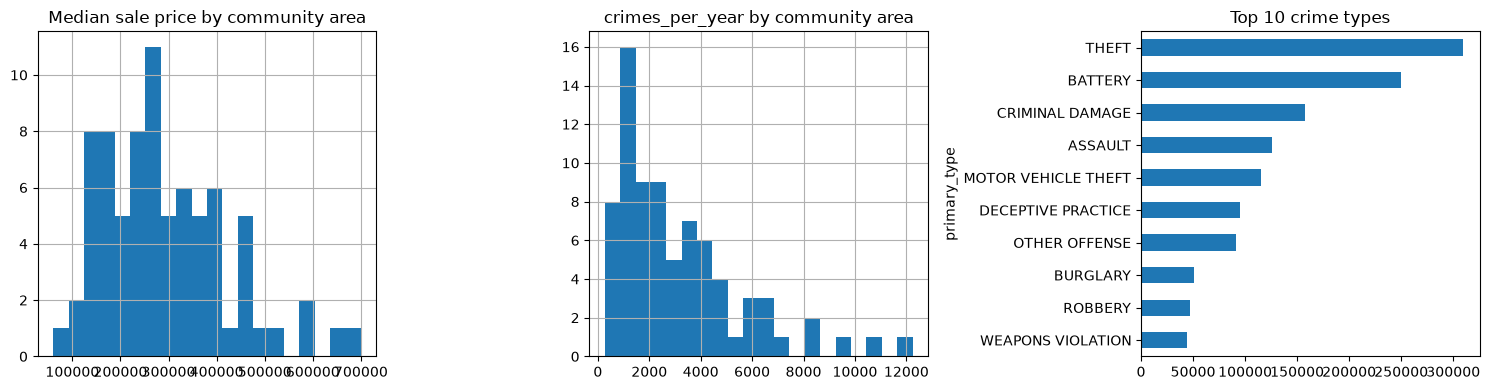

Sales per area: min 122 | median 1487.0


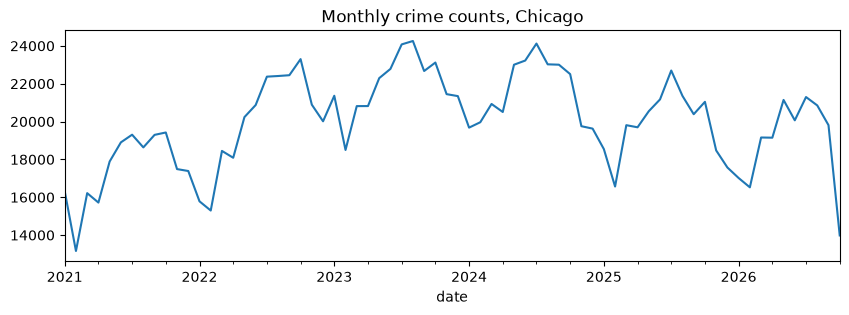

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
table["median_price"].hist(ax=ax[0], bins=20); ax[0].set_title("Median sale price by community area")
table[RATE].hist(ax=ax[1], bins=20); ax[1].set_title(RATE + " by community area")
crime["primary_type"].value_counts().head(10).sort_values().plot.barh(ax=ax[2]); ax[2].set_title("Top 10 crime types")
plt.tight_layout(); plt.show()

print("Sales per area: min", table["n_sales"].min(), "| median", table["n_sales"].median())
crime.groupby(crime["date"].dt.to_period("M")).size().plot(figsize=(10, 3), title="Monthly crime counts, Chicago")
plt.show()

## 6. Visualization testing a hypothesis
**Why this hypothesis:** [TODO: Currently doesn't support hypothesis. Crime counts probably need to be normalized for neighborhood populations.

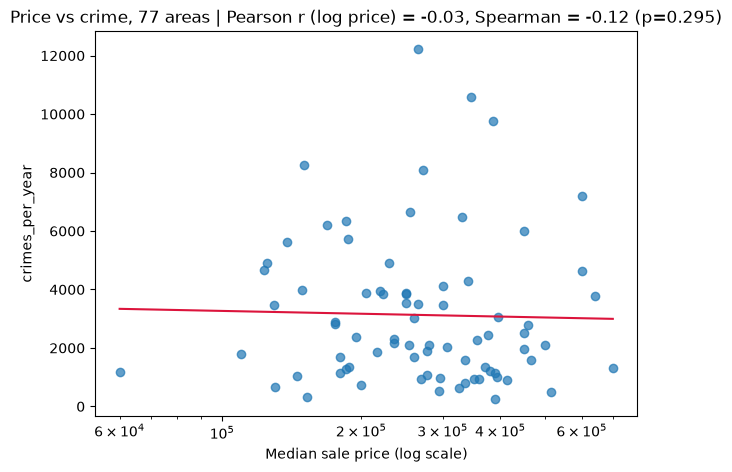

In [27]:
d = table.dropna(subset=["median_price", RATE])
x, y = np.log10(d["median_price"]), d[RATE]
r = np.corrcoef(x, y)[0, 1]
from scipy.stats import spearmanr
rho, p = spearmanr(d["median_price"], d[RATE])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d["median_price"], y, alpha=.7)
m, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(10**xs, m * xs + b, color="crimson")
ax.set_xscale("log"); ax.set_xlabel("Median sale price (log scale)"); ax.set_ylabel(RATE)
ax.set_title(f"Price vs crime, 77 areas | Pearson r (log price) = {r:.2f}, Spearman = {rho:.2f} (p={p:.3g})")
plt.show()

[TODO: interpret the plot in words. Is the relationship what you expected? Any outliers (e.g. the Loop / Near North Side have high crime counts because of daytime population)?]

## 7. ML analysis with baseline
[TODO:]

[TODO: After making model, interpret. Does the model beat the baseline? ]

## 8. Reflection
Answer each question in 2 to 4 sentences, using your real results.
1. Hardest part so far? [TODO]
2. Initial insights? [TODO]
3. Concrete results to show? [TODO]
4. Biggest problems going forward? [TODO]
5. On track? What needs more time? [TODO]
6. Worth proceeding? Why / how would you change it? [TODO]

## 9. Next steps ()
- [TODO] Add population / census income to normalize crime and control for neighborhood wealth.
- [TODO] A second ML or stats method (for example, panel regression over years, or classification of high vs low crime areas).
- [TODO] Choropleth maps of price and crime rate; time trend analysis.
- How we will evaluate success: [TODO.]

## 10. Generative AI suggestions
**Model(s) used:** [TODO]

**Prompts:** [TODO:]

**Output:**
> [TODO: paste at least five suggestions here]